# Klasifikasi Kelangsungan Hidup Karakter Game of Thrones
---

## 1. Business Understanding

### 1.1 Latar Belakang, Masalah, dan Solusi
1. **Latar Belakang**: Sebuah platform analisis media dan penerbitan buku novel ingin membangun sistem kecerdasan buatan berbasis Machine Learning untuk memprediksi tingkat kelangsungan hidup (survival rate) atau potensi kematian karakter dalam serial novel populer Game of Thrones / A Song of Ice and Fire secara otomatis.
2. **Masalah**: Platform tersebut masih menganalisis dan memprediksi tingkat kelangsungan hidup (*survival rate*) secara manual yang memakan waktu.
3. **Solusi**: Membangun model *machine learning* dengan algoritma **Random Forest** dengan memanfaatkan atribut demografis, latar belakang klan/house.

### 1.2 Deskripsi Kolom Dataset `HW2.csv`
| **Nama Kolom** | **Tipe Data** | **Keterangan** |
| :-- | :-- | :-- |
| `S.No` | `int64` | Nomor urut identifikasi data |
| `plod` | `float64` | Nilai estimasi probabilitas kematian berdasarkan analisis statistik (Probability of Life or Death). |
| `name` | `str` | Nama lengkap karakter. |
| `title` | `str` | Gelar/jabatan karakter (misal: Lord, Ser, Queen). |
| `gender` | `int64` | Jenis kelamin karakter (Kategori biner: 1 untuk Pria, 0 untuk Wanita). |
| `culture` | `str` | atar belakang kebudayaan/suku asal karakter (misal: Rivermen, Dornish, Northmen). |
| `dateOfBirth` | `float64` | Tahun kelahiran karakter (satuan: Tahun/Era Westeros). |
| `DateoFdeath` | `float64` | Tahun kematian karakter (jika sudah meninggal). |
| `mother` | `str` | Nama ibu dari karakter. |
| `father` | `str` | Nama ayah dari karakter. |
| `heir` | `str` | Nama ahli waris dari karakter. |
| `house` | `str` | Nama klan/keluarga (House) utama (misal: House Stark, House Lannister, House Targaryen). |
| `spouse` | `str` | Nama pasangan/suami/istri dari karakter. |
| `book1` | `int64` | Indikator kemunculan karakter pada Buku 1 (A Game of Thrones) (Kategori biner: 1 muncul, 0 tidak). |
| `book2` | `int64` | Indikator kemunculan karakter pada Buku 2 (A Clash of Kings) (Kategori biner: 1 muncul, 0 tidak). |
| `book3` | `int64` | Indikator kemunculan karakter pada Buku 3 (A Storm of Swords) (Kategori biner: 1 muncul, 0 tidak). |
| `book4` | `int64` | Indikator kemunculan karakter pada Buku 4 (A Feast for Crows) (Kategori biner: 1 muncul, 0 tidak). |
| `book5` | `int64` | Indikator kemunculan karakter pada Buku 5 (A Dance with Dragons) (Kategori biner: 1 muncul, 0 tidak). |
| `isAliveMother` | `float64` | Status kelangsungan hidup ibu karakter (Kategori biner: 1 hidup, 0 meninggal). |
| `isAliveFather` | `float64` | Status kelangsungan hidup ayah karakter (Kategori biner: 1 hidup, 0 meninggal). |
| `isAliveHeir` | `float64` | Status kelangsungan hidup ahli waris (Kategori biner: 1 hidup, 0 meninggal). |
| `isAliveSpouse` | `float64` | Status kelangsungan hidup pasangan (Kategori biner: 1 hidup, 0 meninggal). |
| `isMarried` | `int64` | Status pernikahan karakter (Kategori biner: 1 menikah, 0 tidak). |
| `isNoble` | `int64` | Status kebangsawaan karakter (Kategori biner: 1 bangsawan, 0 rakyat biasa). |
| `age` | `float64` | Usia karakter (satuan: Tahun) |
| `numDeadRelations` | `int64` | Jumlah kerabat/keluarga dekat karakter yang telah meninggal (satuan: Orang). |
| `boolDeadRelations` | `int64` | Indikator apakah karakter memiliki kerabat yang meninggal (Kategori biner: 1 ya, 0 tidak). |
| `isPopular` | `int64` | Indikator apakah karakter merupakan tokoh populer (Kategori biner: 1 ya, 0 tidak). | 
| `popularity` | `float64` | Skor tingkat popularitas karakter dalam cerita (satuan: Skala rasio 0.0 sampai 1.0). |
| `isAlive` | `int64` | Status kelangsungan hidup karakter (0 = Karakter Meninggal, 1 = Karakter Masih Hidup).|

---
## 2. Data Preparation

### 2.1 Import Library

In [74]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load Dataset

In [75]:
df = pd.read_csv('HW2.csv')
df.columns = df.columns.str.strip().str.title()

### 2.3 Tampilkan Data Teratas dan Data Terbawah

In [76]:
df.head()

,S.No,Plod,Name,Title,Gender,Culture,Dateofbirth,Dateofdeath,Mother,Father,...,Isaliveheir,Isalivespouse,Ismarried,Isnoble,Age,Numdeadrelations,Booldeadrelations,Ispopular,Popularity,Isalive
0,1,0.946,Viserys II Targaryen,NaN,1,NaN,NaN,NaN,Rhaenyra Targaryen,Daemon Targaryen,...,0.0,NaN,0,0,NaN,11,1,1,0.605351,0
1,2,0.613,Walder Frey,Lord of the Crossing,1,Rivermen,208.0,NaN,NaN,NaN,...,NaN,1.0,1,1,97.0,1,1,1,0.896321,1
2,3,0.507,Addison Hill,Ser,1,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0,1,NaN,0,0,0,0.267559,1
3,4,0.924,Aemma Arryn,Queen,0,NaN,82.0,105.0,NaN,NaN,...,NaN,0.0,1,1,23.0,0,0,0,0.183946,0
4,5,0.383,Sylva Santagar,Greenstone,0,Dornish,276.0,NaN,NaN,NaN,...,NaN,1.0,1,1,29.0,0,0,0,0.043478,1


In [77]:
df.tail()

,S.No,Plod,Name,Title,Gender,Culture,Dateofbirth,Dateofdeath,Mother,Father,...,Isaliveheir,Isalivespouse,Ismarried,Isnoble,Age,Numdeadrelations,Booldeadrelations,Ispopular,Popularity,Isalive
1941,1942,0.197,Luwin,NaN,1,Westeros,NaN,299.0,NaN,NaN,...,NaN,NaN,0,0,NaN,0,0,1,0.351171,0
1942,1943,0.013,Reek,NaN,1,NaN,NaN,299.0,NaN,NaN,...,NaN,NaN,0,0,NaN,0,0,0,0.096990,0
1943,1944,0.480,Symeon Star-Eyes,NaN,1,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0,0,NaN,0,0,0,0.030100,1
1944,1945,0.363,Coldhands,NaN,1,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0,0,NaN,0,0,0,0.130435,1
1945,1946,0.907,Tytos Lannister,Casterly Rock,1,NaN,220.0,267.0,NaN,NaN,...,NaN,1.0,1,1,47.0,4,1,0,0.210702,0


### 2.4 Tampilkan Informasi Data

In [78]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1946 entries, 0 to 1945
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No               1946 non-null   int64  
 1   Plod               1946 non-null   float64
 2   Name               1946 non-null   str    
 3   Title              938 non-null    str    
 4   Gender             1946 non-null   int64  
 5   Culture            677 non-null    str    
 6   Dateofbirth        433 non-null    float64
 7   Dateofdeath        444 non-null    float64
 8   Mother             21 non-null     str    
 9   Father             26 non-null     str    
 10  Heir               23 non-null     str    
 11  House              1519 non-null   str    
 12  Spouse             276 non-null    str    
 13  Book1              1946 non-null   int64  
 14  Book2              1946 non-null   int64  
 15  Book3              1946 non-null   int64  
 16  Book4              1946 non-null   

### 2.5 Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Data Duplikat

In [79]:
print(f'Dimensi Data: {df.shape}')
print(f'Jumlah Data: {df.size}')

print(f'\nJumlah Missing Value: {df.isnull().sum().sum()}')
print(f'\n==== Jumlah Missing Value per Kolom ====\n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'Jumlah Data Duplikat: {df.duplicated().sum()}')

Dimensi Data: (1946, 30)
Jumlah Data: 58380

Jumlah Missing Value: 22108

==== Jumlah Missing Value per Kolom ====
Title            1008
Culture          1269
Dateofbirth      1513
Dateofdeath      1502
Mother           1925
Father           1920
Heir             1923
House             427
Spouse           1670
Isalivemother    1925
Isalivefather    1920
Isaliveheir      1923
Isalivespouse    1670
Age              1513
dtype: int64
Jumlah Data Duplikat: 0


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Tampilkan Deskripsi Data

In [80]:
df.describe()

,S.No,Plod,Gender,Dateofbirth,Dateofdeath,Book1,Book2,Book3,Book4,Book5,...,Isaliveheir,Isalivespouse,Ismarried,Isnoble,Age,Numdeadrelations,Booldeadrelations,Ispopular,Popularity,Isalive
count,1946.000000,1946.000000,1946.000000,433.000000,444.000000,1946.000000,1946.000000,1946.000000,1946.000000,1946.000000,...,23.000000,276.000000,1946.000000,1946.000000,433.000000,1946.000000,1946.000000,1946.000000,1946.000000,1946.000000
mean,973.500000,0.365530,0.619219,1577.364896,2950.193694,0.198356,0.374615,0.480473,0.591984,0.395170,...,0.652174,0.778986,0.141829,0.460946,-1293.563510,0.305755,0.074512,0.059096,0.089584,0.745632
std,561.906131,0.312637,0.485704,19565.414460,28192.245529,0.398864,0.484148,0.499747,0.491593,0.489013,...,0.486985,0.415684,0.348965,0.498601,19564.340993,1.383910,0.262669,0.235864,0.160568,0.435617
min,1.000000,0.000000,0.000000,-28.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,-298001.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,487.250000,0.101000,0.000000,240.000000,282.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,18.000000,0.000000,0.000000,0.000000,0.013378,0.000000
50%,973.500000,0.264500,1.000000,268.000000,299.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,1.000000,1.000000,0.000000,0.000000,27.000000,0.000000,0.000000,0.000000,0.033445,1.000000
75%,1459.750000,0.608750,1.000000,285.000000,299.000000,0.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,0.000000,1.000000,50.000000,0.000000,0.000000,0.000000,0.086957,1.000000
max,1946.000000,1.000000,1.000000,298299.000000,298299.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,100.000000,15.000000,1.000000,1.000000,1.000000,1.000000


### 3.2 Anallisis Outlier Pada kolom Numerik

In [81]:
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()

outliers = []

for col in numeric_columns:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        mean = df[col].mean()
        median = df[col].median()
        std = df[col].std()
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z_score = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'standard deviasi': std,
            'min': df[col].min(),
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': df[col].max(),
            'lower bound': lower,
            'upper bound': upper,
            'jumlah outlier (IQR)': outlier_iqr.shape[0],
            'jumlah outlier (Z-Score)': outlier_z_score.shape[0]
        })
        
pd.DataFrame(outliers)

,nama kolom,mean,standard deviasi,min,q1,median,q3,max,lower bound,upper bound,jumlah outlier (IQR),jumlah outlier (Z-Score)
0,S.No,973.500000,561.906131,1.0,487.250000,973.500000,1459.750000,1946.0,-971.500000,2918.500000,0,0
1,Plod,0.365530,0.312637,0.0,0.101000,0.264500,0.608750,1.0,-0.660625,1.370375,0,0
2,Gender,0.619219,0.485704,0.0,0.000000,1.000000,1.000000,1.0,-1.500000,2.500000,0,0
3,Dateofbirth,1577.364896,19565.414460,-28.0,240.000000,268.000000,285.000000,298299.0,172.500000,352.500000,55,2
4,Dateofdeath,2950.193694,28192.245529,0.0,282.000000,299.000000,299.000000,298299.0,256.500000,324.500000,100,4
5,Book1,0.198356,0.398864,0.0,0.000000,0.000000,0.000000,1.0,0.000000,0.000000,386,0
6,Book2,0.374615,0.484148,0.0,0.000000,0.000000,1.000000,1.0,-1.500000,2.500000,0,0
7,Book3,0.480473,0.499747,0.0,0.000000,0.000000,1.000000,1.0,-1.500000,2.500000,0,0
8,Book4,0.591984,0.491593,0.0,0.000000,1.000000,1.000000,1.0,-1.500000,2.500000,0,0
9,Book5,0.395170,0.489013,0.0,0.000000,0.000000,1.000000,1.0,-1.500000,2.500000,0,0


### 3.3 Visualisasi Outlier Dengan Boxplot

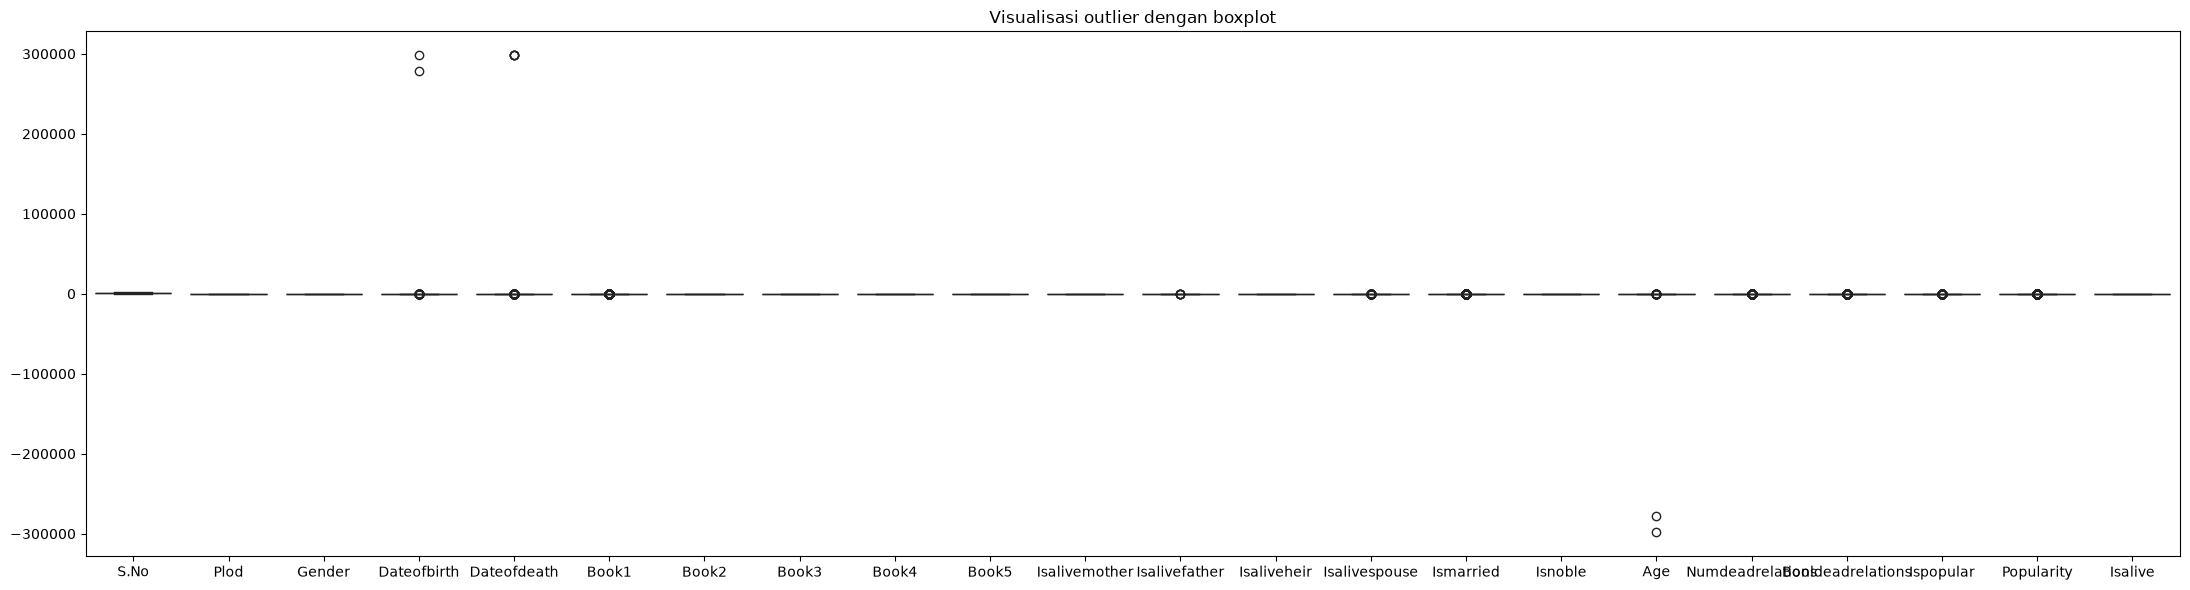

In [82]:
plt.figure(figsize=(22, 6))
sns.boxplot(data=df[numeric_columns], palette='viridis')
plt.title('Visualisasi outlier dengan boxplot')
plt.tight_layout()
plt.show()

### 3.4 Distribusi Variabel Numerik Utama

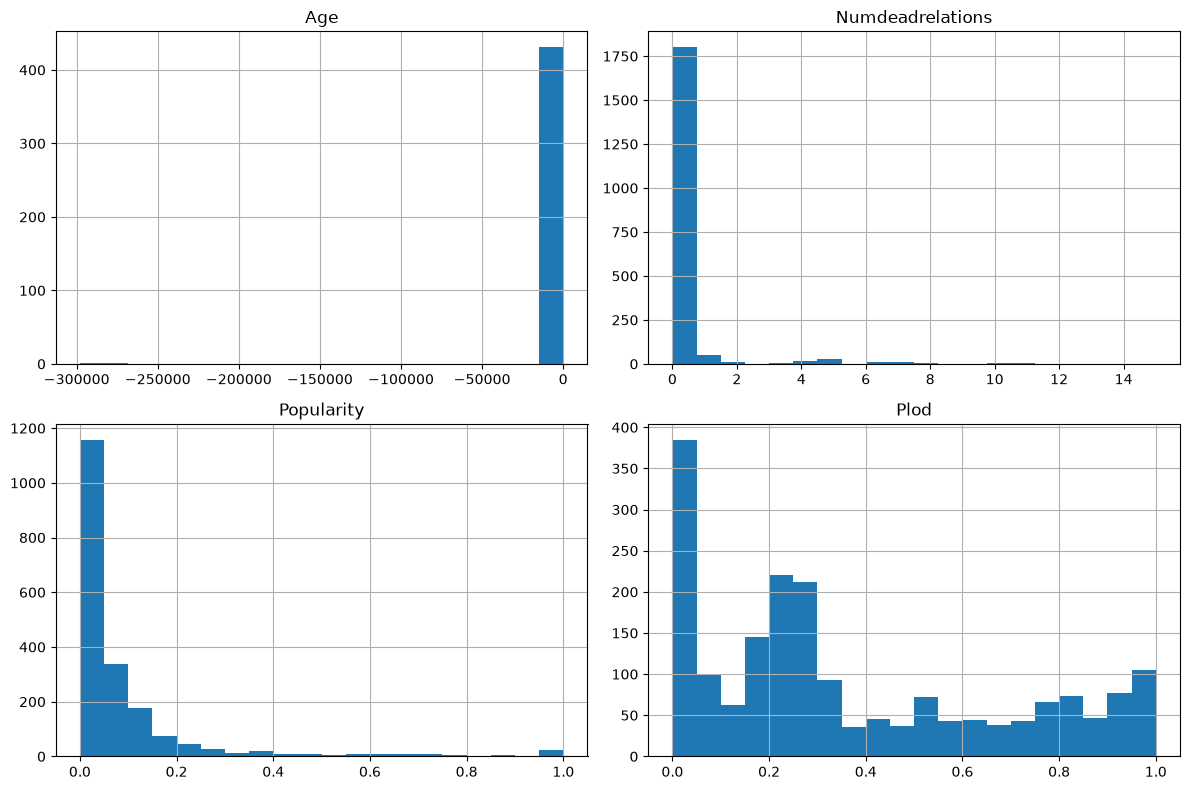

In [83]:
numeric_cols = [ 'Age', 'Numdeadrelations', 'Popularity', 'Plod' ]

df[numeric_cols].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

### 3.5 Visualisasi Jumlah Karakter per Buku

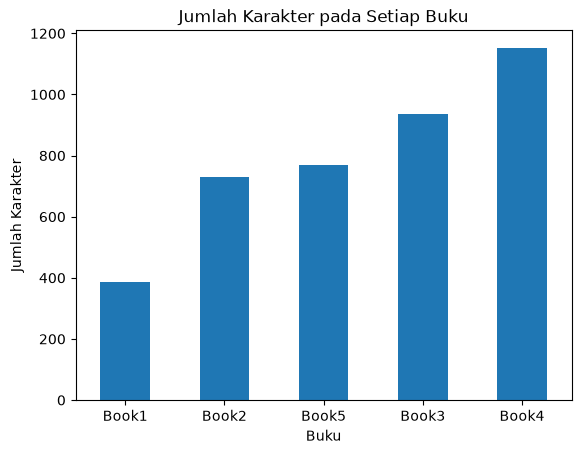

In [84]:
book_cols = ['Book1', 'Book2', 'Book3', 'Book4', 'Book5']

book_counts = df[book_cols].sum().sort_values()

book_counts.plot(kind='bar')
plt.title('Jumlah Karakter pada Setiap Buku')
plt.xlabel('Buku')
plt.ylabel('Jumlah Karakter')
plt.xticks(rotation=0)
plt.show()

### 3.6 Distribusi Target (`isAlive`)

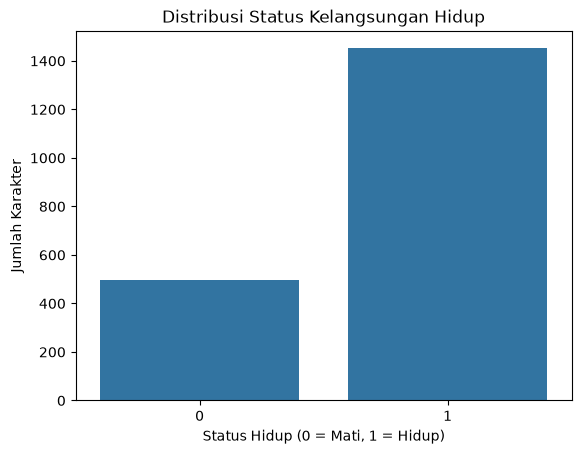

In [85]:
sns.countplot(data=df, x='Isalive')
plt.title('Distribusi Status Kelangsungan Hidup')
plt.xlabel('Status Hidup (0 = Mati, 1 = Hidup)')
plt.ylabel('Jumlah Karakter')
plt.show()

### 3.7 Analisis Korelasi Pada Kolom Numerik Dengan Heatmap

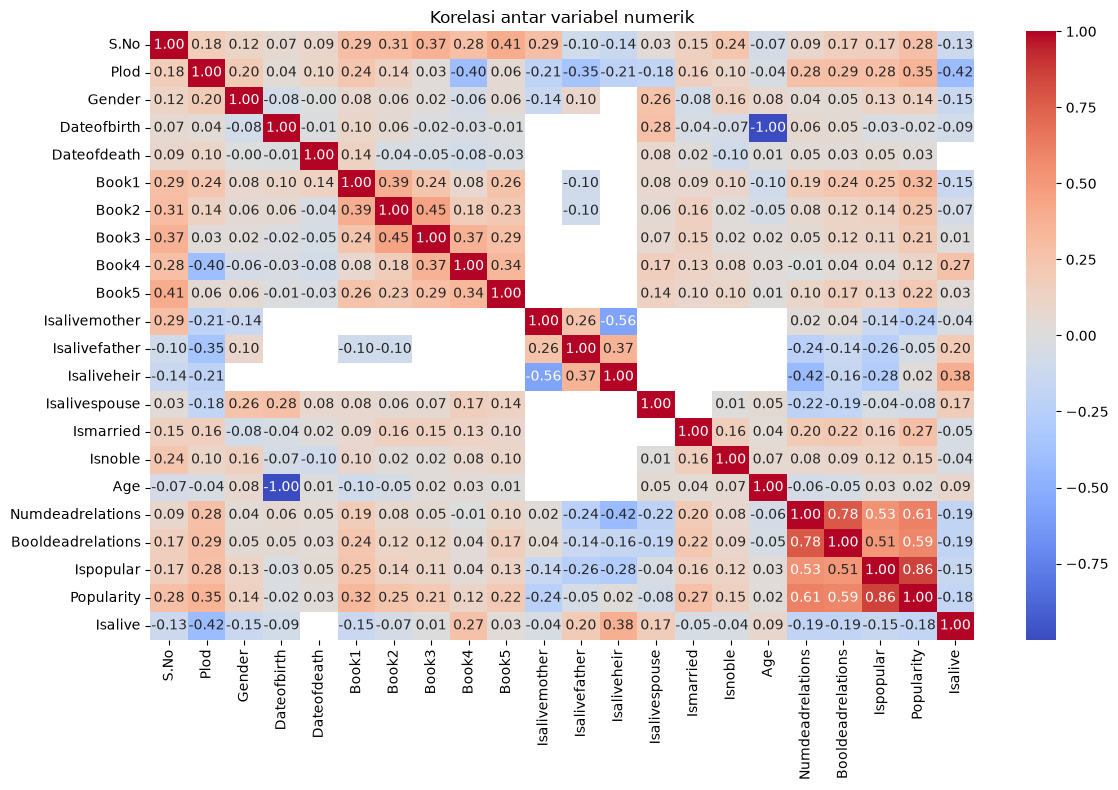

In [86]:
var_list = numeric_columns

plt.figure(figsize=(12, 8))
sns.heatmap(df[var_list].corr(method='pearson'), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi antar variabel numerik')
plt.tight_layout()
plt.show()

---

## 4. Data Preprocessing

### 4.1 Memeriksa Missing Value dan Duplikat Data

In [87]:
print("--- Jumlah Missing Value ---")
print(df.isnull().sum())
print("\n--- Jumlah Duplikat Data ---")
print(df.duplicated().sum())

--- Jumlah Missing Value ---
S.No                    0
Plod                    0
Name                    0
Title                1008
Gender                  0
Culture              1269
Dateofbirth          1513
Dateofdeath          1502
Mother               1925
Father               1920
Heir                 1923
House                 427
Spouse               1670
Book1                   0
Book2                   0
Book3                   0
Book4                   0
Book5                   0
Isalivemother        1925
Isalivefather        1920
Isaliveheir          1923
Isalivespouse        1670
Ismarried               0
Isnoble                 0
Age                  1513
Numdeadrelations        0
Booldeadrelations       0
Ispopular               0
Popularity              0
Isalive                 0
dtype: int64

--- Jumlah Duplikat Data ---
0


### 4.2 Menangani Missing Value dengan Menghapus Kolom yang Tidak Digunakan dan Mengimputasi berupa Teks maupun Median

In [88]:
df = df.drop(columns=['S.No', 'Name', 'Dateofbirth', 'Dateofdeath', 'Mother', 'Father', 'Heir', 'Isalivemother', 'Isalivefather', 'Isaliveheir', 'Spouse', 'Isalivespouse'])

df.loc[df['Age'] < 0, 'Age'] = np.nan

df['Title'] = df['Title'].fillna("No Title").str.strip().str.title()
df['Culture'] = df['Culture'].fillna("Unknown").str.strip().str.lower()
df['House'] = df['House'].fillna("Unknown").str.strip().str.lower()
df['Age'] = df['Age'].fillna(df['Age'].median())
df.isnull().sum()

Plod                 0
Title                0
Gender               0
Culture              0
House                0
Book1                0
Book2                0
Book3                0
Book4                0
Book5                0
Ismarried            0
Isnoble              0
Age                  0
Numdeadrelations     0
Booldeadrelations    0
Ispopular            0
Popularity           0
Isalive              0
dtype: int64

### 4.3 Mengubah Kolom yang Berisi Teks Menjadi Nilai yang Bersifat Unik

In [89]:
df['Title'] = pd.factorize(df['Title'])[0]
df['Culture'] = pd.factorize(df['Culture'])[0]
df['House'] = pd.factorize(df['House'])[0]

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1946 entries, 0 to 1945
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Plod               1946 non-null   float64
 1   Title              1946 non-null   int64  
 2   Gender             1946 non-null   int64  
 3   Culture            1946 non-null   int64  
 4   House              1946 non-null   int64  
 5   Book1              1946 non-null   int64  
 6   Book2              1946 non-null   int64  
 7   Book3              1946 non-null   int64  
 8   Book4              1946 non-null   int64  
 9   Book5              1946 non-null   int64  
 10  Ismarried          1946 non-null   int64  
 11  Isnoble            1946 non-null   int64  
 12  Age                1946 non-null   float64
 13  Numdeadrelations   1946 non-null   int64  
 14  Booldeadrelations  1946 non-null   int64  
 15  Ispopular          1946 non-null   int64  
 16  Popularity         1946 non-null   

### 4.4 Memisahkan Kolom Fitur dan Kolom Target Serta Membagi Data Latih 80% dan Data Uji 20%

In [90]:
X = df.drop(columns=['Isalive'])
y = df['Isalive']

print(f"Bentuk X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"Bentuk y : {len(y)} label")

np.random.seed(43)
acak = np.random.permutation(len(X))
batas = int(0.8 * len(X))

X_train = X.iloc[acak[:batas]]
X_test = X.iloc[acak[batas:]]
y_train = y.iloc[acak[:batas]]
y_test = y.iloc[acak[batas:]]

print(f"Data Latih : {len(X_train)} baris")
print(f"Data Uji : {len(X_test)} baris")

Bentuk X : 1946 baris, 17 kolom
Bentuk y : 1946 label
Data Latih : 1556 baris
Data Uji : 390 baris


### 4.5 Melakukan Oversampling pada Kolom Target untuk Data yang masih Imbalance

In [91]:
print(f"Distribusi Data Sebelum Oversampling: {y_train.value_counts()}")

index_0 = y_train[y_train == 0].index
index_1 = y_train[y_train == 1].index
np.random.seed(43)
index_0_over = np.random.choice(index_0, size=len(index_1), replace=True)
index_balance = np.concatenate([index_1, index_0_over])
np.random.shuffle(index_balance)

X_train_bal = X_train.loc[index_balance].reset_index(drop=True)
y_train_bal = y_train.loc[index_balance].reset_index(drop=True)

print(f"\nDistribusi Data Setelah Oversampling: {y_train_bal.value_counts()}")

Distribusi Data Sebelum Oversampling: Isalive
1    1167
0     389
Name: count, dtype: int64

Distribusi Data Setelah Oversampling: Isalive
1    1167
0    1167
Name: count, dtype: int64


---

## 5. Modelling

### 5.1 Membuat Class Node Sebagai Struktur Simpul Daun

In [92]:
class Node:
    def __init__(self, feature_index=None, threshold=None, left=None, right=None, *, leaf_value=None):
        self.feature_index = feature_index
        self.threshold = threshold
        self.left = left
        self.right = right
        self.leaf_value = leaf_value

    def is_leaf(self):
        return self.leaf_value is not None

### 5.2 Membuat Pohon Keputusan pada Class DecisionTree 

In [93]:
class DecisionTree:
    def __init__(self, min_samples_split=2, max_depth=10, max_features=None):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.max_features = max_features
        self.root = None

    def fit(self, X, y):
        self.n_sub_features = X.shape[1] if self.max_features is None else min(X.shape[1], self.max_features)
        self.root = self._build_tree(X, y, depth=0)

    def _build_tree(self, X, y, depth):
        n_samples, n_features = X.shape
        if depth >= self.max_depth or len(np.unique(y)) == 1 or n_samples < self.min_samples_split:
            return Node(leaf_value=int(np.bincount(y).argmax()))

        selected_features = np.random.choice(n_features, self.n_sub_features, replace=False)
        best_feature, best_thresh = self._find_best_split(X, y, selected_features)

        if best_feature is None:
            return Node(leaf_value=int(np.bincount(y).argmax()))

        left_mask = X[:, best_feature] <= best_thresh
        left_branch = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        right_branch = self._build_tree(X[~left_mask], y[~left_mask], depth + 1)
        return Node(best_feature, best_thresh, left_branch, right_branch)

    def _find_best_split(self, X, y, feature_indices):
        best_gain, best_feature, best_thresh = -1.0, None, None
        parent_entropy = self._compute_entropy(y)

        for feat in feature_indices:
            col_values = X[:, feat]
            candidates = np.unique(col_values)
            if len(candidates) > 20:
                candidates = np.quantile(candidates, np.linspace(0.05, 0.95, 15))

            for thresh in candidates:
                left_mask = col_values <= thresh
                n_l, n_r = np.sum(left_mask), np.sum(~left_mask)
                if n_l == 0 or n_r == 0:
                    continue

                child_entropy = (n_l / len(y)) * self._compute_entropy(y[left_mask]) + \
                                (n_r / len(y)) * self._compute_entropy(y[~left_mask])
                gain = parent_entropy - child_entropy
                if gain > best_gain:
                    best_gain, best_feature, best_thresh = gain, feat, thresh

        return best_feature, best_thresh

    def _compute_entropy(self, y):
        counts = np.bincount(y)
        probs = counts[counts > 0] / len(y)
        return -np.sum(probs * np.log2(probs))

    def predict(self, X):
        return np.array([self._walk_tree(row, self.root) for row in X])

    def _walk_tree(self, row, node):
        if node.is_leaf():
            return node.leaf_value
        if row[node.feature_index] <= node.threshold:
            return self._walk_tree(row, node.left)
        return self._walk_tree(row, node.right)

### 5.3 Menggabungkan Hasil dari Pohon Keputusan dengan Menggunakan Class RandomForest

In [94]:
class RandomForest:
    def __init__(self, n_trees=20, max_depth=8, min_samples_split=5, max_features=None, seed=43):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.seed = seed
        self.forest = []

    def fit(self, X, y):
        if self.seed is not None:
            np.random.seed(self.seed)
        self.forest = []
        n_samples = X.shape[0]

        for _ in range(self.n_trees):
            boot_index = np.random.choice(n_samples, n_samples, replace=True)
            tree = DecisionTree(self.min_samples_split, self.max_depth, self.max_features)
            tree.fit(X[boot_index], y[boot_index])
            self.forest.append(tree)

    def predict(self, X):
        all_preds = np.array([tree.predict(X) for tree in self.forest])
        return np.array([np.bincount(votes).argmax() for votes in all_preds.T])

### 5.4 Menentukan Hyperparameter yang Terbaik dengan Menggunakan Pengulangan Tuning

In [95]:
X_train_np = X_train_bal.values
y_train_np = y_train_bal.values.astype(int)
X_test_np = X_test.values
y_test_np = y_test.values.astype(int)
n_feature_sqrt = int(np.sqrt(X_train_np.shape[1]))

baseline_rf = RandomForest(n_trees=15, max_depth=8, min_samples_split=5, max_features=n_feature_sqrt, seed=43)
baseline_rf.fit(X_train_np, y_train_np)
print(f"Akurasi Baseline: {np.mean(baseline_rf.predict(X_test_np) == y_test_np) * 100:.2f}%\n")

param_grid = {
    'n_trees': [15, 25],
    'max_depth': [6, 8, 10],
    'min_samples_split': [2, 5, 10]
}

best_f1_dead = -1.0
best_params = {}
best_model = None

for n_t in param_grid['n_trees']:
    for m_d in param_grid['max_depth']:
        for m_s in param_grid['min_samples_split']:
            model = RandomForest(n_t, m_d, m_s, max_features=n_feature_sqrt, seed=43)
            model.fit(X_train_np, y_train_np)
            preds = model.predict(X_test_np)

            acc = np.mean(preds == y_test_np)
            tn = np.sum((y_test_np == 0) & (preds == 0))
            fp = np.sum((y_test_np == 0) & (preds == 1))
            fn = np.sum((y_test_np == 1) & (preds == 0))

            rec_0 = tn / (tn + fp) if (tn + fp) > 0 else 0.0
            prec_0 = tn / (tn + fn) if (tn + fn) > 0 else 0.0
            f1_0 = 2 * (prec_0 * rec_0) / (prec_0 + rec_0) if (prec_0 + rec_0) > 0 else 0.0

            print(f"Trees: {n_t:<2} | Depth: {m_d:<2} | Split: {m_s:<2} => Acc: {acc*100:.2f}% | F1 (Meninggal): {f1_0*100:.2f}%")

            if f1_0 > best_f1_dead:
                best_f1_dead = f1_0
                best_params = {'n_trees': n_t, 'max_depth': m_d, 'min_samples_split': m_s}
                best_model = model

print("\nHyperparameter Terbaik:", best_params)
print(f"F1-Score (Meninggal) Terbaik: {best_f1_dead*100:.2f}%")

Akurasi Baseline: 76.67%

Trees: 15 | Depth: 6  | Split: 2  => Acc: 77.69% | F1 (Meninggal): 61.67%
Trees: 15 | Depth: 6  | Split: 5  => Acc: 77.18% | F1 (Meninggal): 63.07%
Trees: 15 | Depth: 6  | Split: 10 => Acc: 80.51% | F1 (Meninggal): 64.49%
Trees: 15 | Depth: 8  | Split: 2  => Acc: 79.23% | F1 (Meninggal): 64.63%
Trees: 15 | Depth: 8  | Split: 5  => Acc: 76.67% | F1 (Meninggal): 60.61%
Trees: 15 | Depth: 8  | Split: 10 => Acc: 79.23% | F1 (Meninggal): 62.33%
Trees: 15 | Depth: 10 | Split: 2  => Acc: 81.79% | F1 (Meninggal): 67.58%
Trees: 15 | Depth: 10 | Split: 5  => Acc: 80.51% | F1 (Meninggal): 64.81%
Trees: 15 | Depth: 10 | Split: 10 => Acc: 80.77% | F1 (Meninggal): 64.45%
Trees: 25 | Depth: 6  | Split: 2  => Acc: 79.23% | F1 (Meninggal): 63.35%
Trees: 25 | Depth: 6  | Split: 5  => Acc: 77.18% | F1 (Meninggal): 62.45%
Trees: 25 | Depth: 6  | Split: 10 => Acc: 79.74% | F1 (Meninggal): 62.91%
Trees: 25 | Depth: 8  | Split: 2  => Acc: 78.97% | F1 (Meninggal): 63.72%
Trees: 25 | 

---

## 6. Evaluation

### 6.1 Confusion Matrix

In [96]:
y_pred = best_model.predict(X_test_np)

tn = np.sum((y_test_np == 0) & (y_pred == 0))
fp = np.sum((y_test_np == 0) & (y_pred == 1))
fn = np.sum((y_test_np == 1) & (y_pred == 0)) 
tp = np.sum((y_test_np == 1) & (y_pred == 1))

cm = np.array([[tn, fp], [fn, tp]])

print(f"True Negative  (Asli Meninggal, Tebakan Meninggal) : {tn}")
print(f"False Positive (Asli Meninggal, Tebakan Hidup)     : {fp}")
print(f"False Negative (Asli Hidup, Tebakan Meninggal)     : {fn}")
print(f"True Positive  (Asli Hidup, Tebakan Hidup)         : {tp}")
print(f"Total Data Uji                                     : {np.sum(cm)}\n")

True Negative  (Asli Meninggal, Tebakan Meninggal) : 74
False Positive (Asli Meninggal, Tebakan Hidup)     : 32
False Negative (Asli Hidup, Tebakan Meninggal)     : 39
True Positive  (Asli Hidup, Tebakan Hidup)         : 245
Total Data Uji                                     : 390



### 6.2 Hasil Perhitungan Matriks

In [97]:
accuracy = (tp + tn) / (tp + tn + fp + fn)

prec_0 = tn / (tn + fn) if (tn + fn) > 0 else 0.0
rec_0  = tn / (tn + fp) if (tn + fp) > 0 else 0.0
f1_0   = 2 * (prec_0 * rec_0) / (prec_0 + rec_0) if (prec_0 + rec_0) > 0 else 0.0

prec_1 = tp / (tp + fp) if (tp + fp) > 0 else 0.0
rec_1  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
f1_1   = 2 * (prec_1 * rec_1) / (prec_1 + rec_1) if (prec_1 + rec_1) > 0 else 0.0

macro_prec = (prec_0 + prec_1) / 2
macro_rec  = (rec_0 + rec_1) / 2
macro_f1   = (f1_0 + f1_1) / 2

print(f"Accuracy Total : {accuracy * 100:.2f}% ({tp + tn} dari {tp + tn + fp + fn} data uji benar)\n")
print(f"{'Kelas':<18} | {'Precision':<10}| {'Recall':<10}| {'F1-Score':<10}")
print(f"{'0 (Meninggal)':<18} | {prec_0 * 100:>8.2f}% | {rec_0 * 100:>8.2f}% | {f1_0 * 100:>8.2f}%")
print(f"{'1 (Hidup)':<18} | {prec_1 * 100:>8.2f}% | {rec_1 * 100:>8.2f}% | {f1_1 * 100:>8.2f}%")
print(f"{'Macro Average':<18} | {macro_prec * 100:>8.2f}% | {macro_rec * 100:>8.2f}% | {macro_f1 * 100:>8.2f}%")

Accuracy Total : 81.79% (319 dari 390 data uji benar)

Kelas              | Precision | Recall    | F1-Score  
0 (Meninggal)      |    65.49% |    69.81% |    67.58%
1 (Hidup)          |    88.45% |    86.27% |    87.34%
Macro Average      |    76.97% |    78.04% |    77.46%


### 6.3 Visualisasi Confusion Matrix dan Hasil Perhitungan Matriks

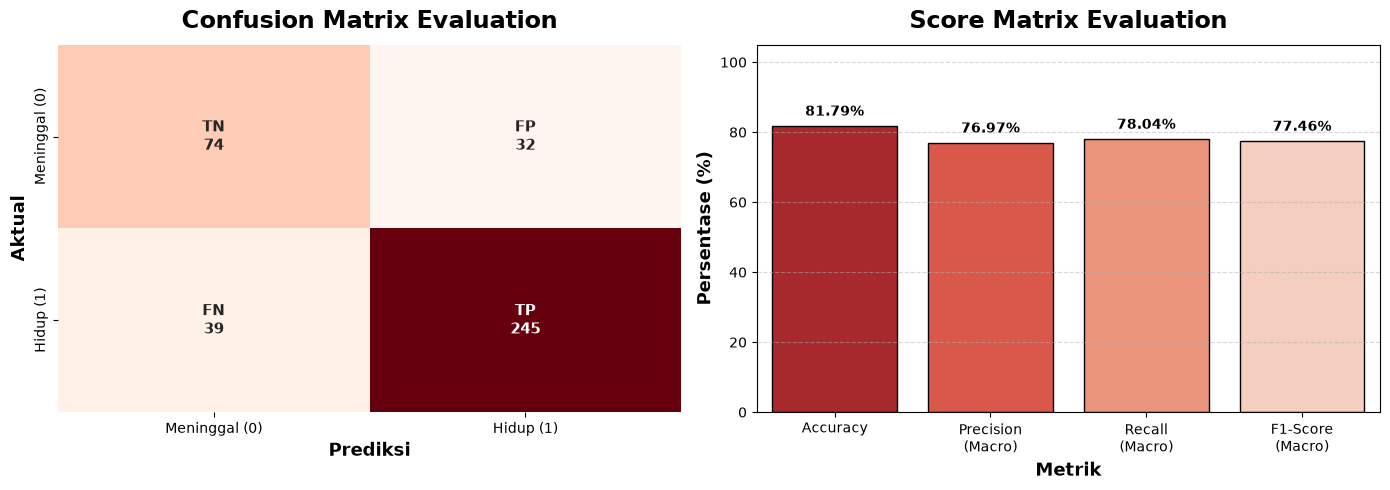

In [98]:
result = pd.DataFrame({
    'Matriks': ['Accuracy', 'Precision\n(Macro)', 'Recall\n(Macro)', 'F1-Score\n(Macro)'],
    'Percentage': [accuracy * 100, macro_prec * 100, macro_rec * 100, macro_f1 * 100]
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

group_names = ['TN', 'FP', 'FN', 'TP']
group_counts = [f"{value:0.0f}" for value in cm.flatten()]
labels = np.asarray([f"{v1}\n{v2}" for v1, v2 in zip(group_names, group_counts)]).reshape(2, 2)

sns.heatmap(cm, annot=labels, fmt='', cmap='Reds', cbar=False, xticklabels=['Meninggal (0)', 'Hidup (1)'], yticklabels=['Meninggal (0)', 'Hidup (1)'], annot_kws={"size": 11, "weight": "bold"}, ax=axes[0])
axes[0].set_title('Confusion Matrix Evaluation', fontsize=17, fontweight='bold', pad=12)
axes[0].set_xlabel('Prediksi', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Aktual', fontsize=13, fontweight='bold')

sns.barplot(data=result, x='Matriks', y='Percentage', hue='Matriks', palette='Reds_r', legend=False, edgecolor='black', ax=axes[1])

for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'{height:.2f}%', (p.get_x() + p.get_width() / 2., height), ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points')

axes[1].set_title('Score Matrix Evaluation', fontsize=17, fontweight='bold', pad=12)
axes[1].set_xlabel('Metrik', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Persentase (%)', fontsize=13, fontweight='bold')
axes[1].set_ylim(0, 105)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 7. GUI

In [99]:
def to_binary(value):
    return 1 if value == "Ya" else 0


def predict_isAlive():
    try:
        gender_value = entryGender.get()

        if gender_value == "Laki-Laki":
            gender = 1
        elif gender_value == "Perempuan":
            gender = 0
        else:
            raise ValueError(
                "Gender harus dipilih sebagai Laki-Laki atau Perempuan."
            )

        age = float(entryAge.get())

        book1 = to_binary(entryBook1.get())
        book2 = to_binary(entryBook2.get())
        book3 = to_binary(entryBook3.get())
        book4 = to_binary(entryBook4.get())
        book5 = to_binary(entryBook5.get())

        is_married = to_binary(entryIsMarried.get())
        is_noble = to_binary(entryIsNoble.get())
        bool_dead_relations = to_binary(entryBoolDeadRelations.get())

        num_dead_relations = int(entryNumDeadRelations.get())
        is_popular = to_binary(entryIsPopular.get())
        popularity = float(entryPopularity.get())
        plod = float(entryPlod.get())

        if age < 0:
            raise ValueError("Age tidak boleh bernilai negatif.")

        if num_dead_relations < 0:
            raise ValueError(
                "Jumlah kerabat yang meninggal tidak boleh negatif."
            )

        if not 0 <= popularity <= 1:
            raise ValueError(
                "Popularity harus berada di antara 0 dan 1."
            )

        if not 0 <= plod <= 1:
            raise ValueError(
                "PLOD harus berada di antara 0 dan 1."
            )

        if num_dead_relations == 0:
            bool_dead_relations = 0

        if num_dead_relations > 0:
            bool_dead_relations = 1

        gui_values = {
            "gender": gender,
            "age": age,
            "book1": book1,
            "book2": book2,
            "book3": book3,
            "book4": book4,
            "book5": book5,
            "ismarried": is_married,
            "isnoble": is_noble,
            "booldeadrelations": bool_dead_relations,
            "numdeadrelations": num_dead_relations,
            "ispopular": is_popular,
            "popularity": popularity,
            "plod": plod
        }
        
        default_values = X_train.mode().iloc[0].to_dict()

        for column in X_train.columns:
            normalized_column = column.lower().replace("_", "")

            if normalized_column in gui_values:
                default_values[column] = gui_values[normalized_column]

        input_data = pd.DataFrame(
            [[default_values[column] for column in X_train.columns]],
            columns=X_train.columns
        )

        input_array = input_data.to_numpy(dtype=float)

        prediction = best_model.predict(input_array)[0]

        if prediction == 1:
            lblPredictionResult.configure(
                text="Prediksi: Karakter ini kemungkinan akan hidup.",
                text_color="green"
            )
        else:
            lblPredictionResult.configure(
                text="Prediksi: Karakter ini kemungkinan akan mati.",
                text_color="red"
            )

        print("Data input model:")
        print(input_data)

    except ValueError as error:
        lblPredictionResult.configure(
            text=f"Error: {error}",
            text_color="red"
        )

In [101]:
from customtkinter import *

app = CTk()
app.title("Klasifikasi Kelangsungan Hidup Karakter Game of Thrones")

lebar = 600
tinggi = 700
screen_width = app.winfo_screenwidth()
screen_height = app.winfo_screenheight()
x = int((screen_width / 2) - (lebar / 2))
y = int((screen_height / 2) - (tinggi / 2))
app.geometry(f"{lebar}x{tinggi}+{x}+{y}")
set_appearance_mode("light")

MainFrame = CTkScrollableFrame(app, fg_color="#fff", corner_radius=12)
MainFrame.pack(padx=20, pady=20, fill="both", expand=True)

lblGender = CTkLabel(MainFrame, text="Jenis Kelamin", font=("Arial", 16), justify="left")
lblGender.pack(pady=5, padx=10, anchor="w")
entryGender = CTkSegmentedButton(MainFrame, values=["Laki-Laki", "Perempuan"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryGender.pack(pady=(0, 5), padx=10, fill="x")

lblAge = CTkLabel(MainFrame, text="Usia", font=("Arial", 16), justify="left")
lblAge.pack(pady=5, padx=10, anchor="w")
entryAge = CTkEntry(MainFrame, placeholder_text="Masukkan usia karakter", font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryAge.pack(pady=(0, 5), padx=10, fill="x")

lblBook1 = CTkLabel(MainFrame, text="Apakah karakter muncul di buku A Game of Thrones?", font=("Arial", 16))
lblBook1.pack(pady=5, padx=10, anchor="w")
entryBook1 = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryBook1.pack(pady=(0, 10), padx=10, fill="x")

lblBook2 = CTkLabel(MainFrame, text="Apakah karakter muncul di buku A Clash of Kings?", font=("Arial", 16))
lblBook2.pack(pady=5, padx=10, anchor="w")
entryBook2 = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryBook2.pack(pady=(0, 10), padx=10, fill="x")

lblBook3 = CTkLabel(MainFrame, text="Apakah karakter muncul di buku A Storm of Swords?", font=("Arial", 16))
lblBook3.pack(pady=5, padx=10, anchor="w")
entryBook3 = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryBook3.pack(pady=(0, 10), padx=10, fill="x")

lblBook4 = CTkLabel(MainFrame, text="Apakah karakter muncul di buku A Feast for Crows?", font=("Arial", 16))
lblBook4.pack(pady=5, padx=10, anchor="w")
entryBook4 = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryBook4.pack(pady=(0, 10), padx=10, fill="x")

lblBook5 = CTkLabel(MainFrame, text="Apakah karakter muncul di buku A Dance with Dragons?", font=("Arial", 16))
lblBook5.pack(pady=5, padx=10, anchor="w")
entryBook5 = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryBook5.pack(pady=(0, 10), padx=10, fill="x")

lblIsMarried = CTkLabel(MainFrame, text="Apakah karakter menikah?", font=("Arial", 16))
lblIsMarried.pack(pady=5, padx=10, anchor="w")
entryIsMarried = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryIsMarried.pack(pady=(0, 10), padx=10, fill="x")

lblIsNoble = CTkLabel(MainFrame, text="Apakah karakter bangsawan?", font=("Arial", 16))
lblIsNoble.pack(pady=5, padx=10, anchor="w")
entryIsNoble = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryIsNoble.pack(pady=(0, 10), padx=10, fill="x")

lblBoolDeadRelations = CTkLabel(MainFrame, text="Apakah karakter memiliki kerabat yang mati?", font=("Arial", 16))
lblBoolDeadRelations.pack(pady=5, padx=10, anchor="w")
entryBoolDeadRelations = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryBoolDeadRelations.pack(pady=(0, 10), padx=10, fill="x")

lblNumDeadRelations = CTkLabel(MainFrame, text="Jumlah kerabat yang mati", font=("Arial", 16), justify="left")
lblNumDeadRelations.pack(pady=5, padx=10, anchor="w")
entryNumDeadRelations = CTkEntry(MainFrame, placeholder_text="Masukkan jumlah kerabat yang mati", font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryNumDeadRelations.pack(pady=(0, 5), padx=10, fill="x")

lblIsPopular = CTkLabel(MainFrame, text="Apakah karakter populer?", font=("Arial", 16), justify="left")
lblIsPopular.pack(pady=5, padx=10, anchor="w")
entryIsPopular = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryIsPopular.pack(pady=(0, 10), padx=10, fill="x")

lblPopularity = CTkLabel(MainFrame, text="Popularitas karakter", font=("Arial", 16), justify="left")
lblPopularity.pack(pady=5, padx=10, anchor="w")
entryPopularity = CTkEntry(MainFrame, placeholder_text="Masukkan popularitas karakter", font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryPopularity.pack(pady=(0, 5), padx=10, fill="x")

lblPlod = CTkLabel(MainFrame, text="Plod karakter", font=("Arial", 16), justify="left")
lblPlod.pack(pady=5, padx=10, anchor="w")
entryPlod = CTkEntry(MainFrame, placeholder_text="Masukkan plod karakter", font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryPlod.pack(pady=(0, 5), padx=10, fill="x")

btnPredict = CTkButton(app, text="Prediksi Kelangsungan Hidup", font=("Arial", 16), corner_radius=8, command=predict_isAlive)
btnPredict.pack(pady=10, padx=20, fill="x")

lblPredictionResult = CTkLabel(app, text="Hasil Prediksi: -", font=("Arial", 16), justify="center")
lblPredictionResult.pack(pady=10, padx=20, fill="x")

app.mainloop()

Data input model:
    Plod  Title  Gender  Culture  House  Book1  Book2  Book3  Book4  Book5  \
0  0.613    0.0       1      0.0    0.0      1      1      1      1      1   

   Ismarried  Isnoble   Age  Numdeadrelations  Booldeadrelations  Ispopular  \
0          1        1  97.0                 1                  1          1   

   Popularity  
0        0.89  


---
## 8. Conclusion

### 8.1 Kesimpulan Analisis dan Pemodelan

Berdasarkan seluruh rangkaian analisis data, preprocessing, pembangunan model, hingga evaluasi yang telah dilakukan, diperoleh beberapa kesimpulan utama sebagai berikut:

1. Dataset awal terdiri dari **1.946 baris dan 30 kolom**. Pada tahap pembersihan data, beberapa kolom yang tidak relevan atau memiliki terlalu banyak nilai kosong, seperti `S.No`, `Name`, `DateofBirth`, `DateofDeath`, `Mother`, `Father`, `Heir`, `Spouse`, serta informasi kelangsungan hidup anggota keluarga, dihapus dari dataset. Kolom target yang digunakan adalah `Isalive`. [Lihat pemeriksaan data.](#25-memeriksa-dimensi-data-jumlah-data-missing-value-dan-data-duplikat)

2. Pada tahap preprocessing, nilai `Age` yang negatif dianggap tidak valid dan diubah menjadi nilai kosong, kemudian digantikan menggunakan nilai median. Nilai kosong pada kolom `Title`, `Culture`, dan `House` diisi menggunakan kategori seperti `No Title` dan `Unknown`. Selanjutnya, ketiga kolom kategorikal tersebut diubah menjadi nilai numerik menggunakan teknik factorization. Setelah preprocessing selesai, dataset tidak lagi memiliki missing value. Setelah proses preprocessing, data terdiri dari **1.946 baris dan 18 kolom**, yaitu **17 fitur** dan satu kolom target `Isalive`. Fitur yang digunakan meliputi `Plod`, `Title`, `Gender`, `Culture`, `House`, `Book1` hingga `Book5`, `Ismarried`, `Isnoble`, `Age`, `Numdeadrelations`, `Booldeadrelations`, `Ispopular`, dan `Popularity`. Data dibagi menjadi **1.556 data latih (80%)** dan **390 data uji (20%)**. Distribusi kelas pada data latih menunjukkan adanya ketidakseimbangan, yaitu sebanyak **1.167 karakter hidup** dan **389 karakter meninggal**. Untuk mengatasi masalah tersebut, dilakukan oversampling pada kelas minoritas sehingga jumlah data pada kedua kelas menjadi seimbang, masing-masing sebanyak **1.167 data**. [Lihat pemrosesan data.](#41-memeriksa-missing-value-dan-duplikat-data)

3. Berdasarkan proses tuning hyperparameter, konfigurasi model terbaik diperoleh dengan menggunakan **15 pohon (`n_trees=15`)**, kedalaman maksimum **10 (`max_depth=10`)**, dan minimum jumlah data untuk melakukan pemisahan sebesar **2 (`min_samples_split=2`)**. Konfigurasi tersebut menghasilkan akurasi sebesar **81,79%** pada data uji dan F1-Score kelas karakter meninggal sebesar **67,58%**. Hasil evaluasi menunjukkan bahwa model memperoleh akurasi sebesar **81,79%**, dengan **319 dari 390 data uji berhasil diklasifikasikan dengan benar**. Untuk kelas karakter meninggal, model memperoleh precision sebesar **65,49%**, recall sebesar **69,81%**, dan F1-Score sebesar **67,58%**. Sementara itu, untuk kelas karakter hidup, model memperoleh precision sebesar **88,45%**, recall sebesar **86,27%**, dan F1-Score sebesar **87,34%**. [Lihat proses hyperparameter](#54-menentukan-hyperparameter-yang-terbaik-dengan-menggunakan-pengulangan-tuning)